# C2 MF 튜닝

잠재 차원, 정규화 세기, 학습률, neg_ratio를 바꿔 가며 비교하고 최종 설정을 고릅니다(제안서 3.2의 비교 실험).

C1에서 본 것처럼 MF를 용도별로 둘로 나눠 각각 고릅니다.

| 용도 | 학습 | 고르는 기준 (val) |
| --- | --- | --- |
| 별점 예측 (`rating`) | 평점만 학습 (neg_ratio 0) | 검증 RMSE가 가장 낮은 설정 |
| 추천 (`ranking`) | 0점을 함께 학습 (neg_ratio 1 이상) | val NDCG@10이 가장 높은 설정 |

- 한 번에 한 가지 값만 바꾸고, 가장 좋았던 값을 고정한 채 다음 값을 바꿉니다. 모든 조합을 다 돌리면 노트북 한 대로는 시간이 너무 오래 걸립니다.
- 모든 후보는 `train`으로만 학습하고 `val`로만 비교합니다. `test`와 `cold_final`은 쓰지 않습니다.
- 추천 지표는 val 독자 5,000명(시드 고정)으로 잽니다. 모든 후보가 같은 독자로 채점됩니다.
- epoch 수는 따로 바꾸지 않고 early stopping으로 정합니다(검증 점수가 2번 연속 나아지지 않으면 멈추고 가장 좋았던 epoch로 되돌림).
- 결과가 나쁜 후보도 모두 `results/collaborative_filtering/C2_tuning_runs.csv`에 남깁니다.

In [1]:
from dataclasses import asdict, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bookrec.data import load_split
from bookrec.evaluation import evaluate_warm
from bookrec.models.collaborative_filtering import MFConfig
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, TUNING_USERS, run_experiment, save_selected
from bookrec.models.popularity import PopularityRecommender
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()
popularity_ndcg = evaluate_warm(PopularityRecommender().fit(split.train), split, on="val", n_users=TUNING_USERS)["ndcg@10"]
print(f"인기순 기준선 val NDCG@10 = {popularity_ndcg:.4f}")

인기순 기준선 val NDCG@10 = 0.0382


In [2]:
METRIC = {"rating": "val_rmse", "ranking": "val_ndcg@10"}
runs, epoch_histories, finished = [], [], {}

# NOTE: 튜닝은 오래 걸려서 중간에 끊길 수 있다. 이전 실행에서 끝난 실험은 저장된 CSV에서 읽어 다시 돌리지 않는다.
#       처음부터 다시 돌리려면 C2_tuning_runs.csv와 C2_epoch_history.csv를 지우고 실행한다.
RUNS_PATH, EPOCHS_PATH = RESULT_DIR / "C2_tuning_runs.csv", RESULT_DIR / "C2_epoch_history.csv"
if RUNS_PATH.exists():
    defaults = asdict(MFConfig())
    for record in pd.read_csv(RUNS_PATH).to_dict("records"):
        # NOTE: CSV에서 읽으면 정수가 실수로 바뀌는 경우가 있어, 기본 설정의 자료형(int, float)으로 다시 맞춘다.
        config = MFConfig(**{name: type(default)(record[name]) for name, default in defaults.items()})
        finished[(record["purpose"], config)] = record
        runs.append(record)
    epoch_histories.append(pd.read_csv(EPOCHS_PATH))
    print(f"이전에 끝난 실험 {len(runs)}개를 읽었습니다.")


def sweep(purpose: str, base: MFConfig, name: str, values: list) -> MFConfig:
    """base에서 name 값만 values로 바꿔 가며 학습하고, 가장 좋은 값을 넣은 설정을 돌려준다. 이미 돌린 설정은 다시 돌리지 않는다."""
    for value in values:
        # NOTE: dataclasses.replace(객체, 이름=값)은 그 항목만 바꾼 새 설정을 만든다.
        config = replace(base, **{name: value})
        if (purpose, config) not in finished:
            record, model = run_experiment(config, split, purpose)
            record["run_id"] = f"{purpose}-{len(runs) + 1:02d}"
            finished[(purpose, config)] = record
            runs.append(record)
            epoch_histories.append(model.history.assign(run_id=record["run_id"]))
            # NOTE: 중간에 끊겨도 기록이 남도록 실험 하나가 끝날 때마다 저장한다.
            pd.DataFrame(runs).to_csv(RUNS_PATH, index=False)
            pd.concat(epoch_histories).to_csv(EPOCHS_PATH, index=False)
        record = finished[(purpose, config)]
        print(f"[{record['run_id']}] {name}={value}: val RMSE {record['val_rmse']:.4f}, val NDCG@10 {record['val_ndcg@10']:.4f}, "
              f"epoch {record['best_epoch']}/{record['epochs_run']}, {record['train_seconds']:.0f}초")
    table = pd.DataFrame([finished[(purpose, replace(base, **{name: value}))] for value in values])
    # NOTE: RMSE는 낮을수록, NDCG는 높을수록 좋다. idxmin/idxmax는 가장 작은/큰 값이 있는 행의 위치를 돌려준다.
    best_row = table[METRIC[purpose]].idxmin() if purpose == "rating" else table[METRIC[purpose]].idxmax()
    best = replace(base, **{name: values[best_row]})
    print(f"→ {name} = {values[best_row]} 선택\n")
    return best


def sweep_table(purpose: str, base: MFConfig, name: str, values: list) -> pd.DataFrame:
    """그래프와 표에 쓸 (값, 지표) 표를 만든다."""
    rows = [finished[(purpose, replace(base, **{name: value}))] for value in values]
    return pd.DataFrame(rows)[[name, "val_rmse", "val_ndcg@10", "best_epoch", "train_seconds"]]

이전에 끝난 실험 15개를 읽었습니다.


## 1. 별점 예측용 MF (평점만 학습)

출발 설정은 C1과 같습니다(차원 32, 학습률 0.01, 정규화 0.05). 학습률 → 잠재 차원 → 정규화 세기 순서로 바꿉니다.

In [3]:
LR_VALUES = [0.005, 0.01, 0.02]
FACTOR_VALUES = [8, 16, 32, 64]
REG_VALUES = [0.02, 0.05, 0.1]

rating_start = MFConfig(n_factors=32, lr=0.01, reg=0.05, neg_ratio=0, n_epochs=40, patience=2)
rating_after_lr = sweep("rating", rating_start, "lr", LR_VALUES)
rating_after_factors = sweep("rating", rating_after_lr, "n_factors", FACTOR_VALUES)
rating_best = sweep("rating", rating_after_factors, "reg", REG_VALUES)
rating_best

[rating-01] lr=0.005: val RMSE 0.8473, val NDCG@10 0.0029, epoch 39/40, 170초
[rating-02] lr=0.01: val RMSE 0.8477, val NDCG@10 0.0031, epoch 21/23, 99초
[rating-03] lr=0.02: val RMSE 0.8489, val NDCG@10 0.0027, epoch 11/13, 53초
→ lr = 0.005 선택

[rating-04] n_factors=8: val RMSE 0.8496, val NDCG@10 0.0033, epoch 40/40, 57초
[rating-05] n_factors=16: val RMSE 0.8487, val NDCG@10 0.0037, epoch 40/40, 94초
[rating-01] n_factors=32: val RMSE 0.8473, val NDCG@10 0.0029, epoch 39/40, 170초
[rating-06] n_factors=64: val RMSE 0.8463, val NDCG@10 0.0033, epoch 39/40, 290초
→ n_factors = 64 선택

[rating-07] reg=0.02: val RMSE 0.8574, val NDCG@10 0.0064, epoch 17/19, 137초
[rating-06] reg=0.05: val RMSE 0.8463, val NDCG@10 0.0033, epoch 39/40, 290초
[rating-08] reg=0.1: val RMSE 0.8626, val NDCG@10 0.0011, epoch 10/12, 90초
→ reg = 0.05 선택



MFConfig(n_factors=64, lr=0.005, reg=0.05, n_epochs=40, batch_size=2048, neg_ratio=0, patience=2, fold_in_reg=5.0, seed=42)

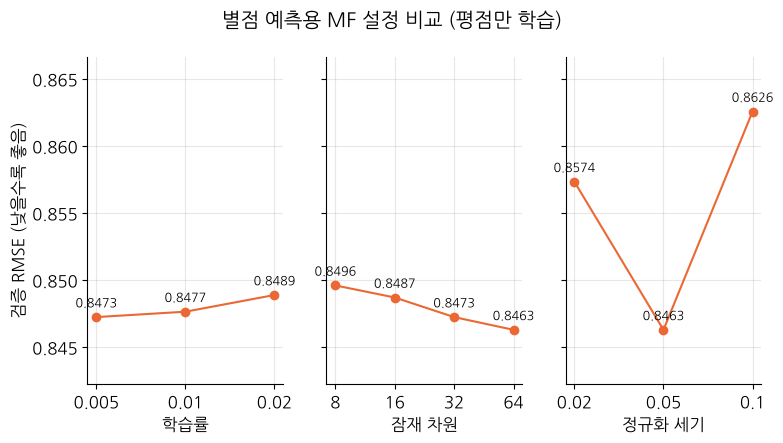

,lr,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,0.005,0.8473,0.0029,39,170.3
1,0.010,0.8477,0.0031,21,99.2
2,0.020,0.8489,0.0027,11,53.1


,n_factors,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,8,0.8496,0.0033,40,57.1
1,16,0.8487,0.0037,40,93.9
2,32,0.8473,0.0029,39,170.3
3,64,0.8463,0.0033,39,289.5


,reg,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,0.02,0.8574,0.0064,17,136.7
1,0.05,0.8463,0.0033,39,289.5
2,0.10,0.8626,0.0011,10,89.5


In [4]:
rating_panels = [
    ("lr", "학습률", sweep_table("rating", rating_start, "lr", LR_VALUES)),
    ("n_factors", "잠재 차원", sweep_table("rating", rating_after_lr, "n_factors", FACTOR_VALUES)),
    ("reg", "정규화 세기", sweep_table("rating", rating_after_factors, "reg", REG_VALUES)),
]
# NOTE: subplots(1, 3, sharey=True)는 가로로 3칸을 만들고 y축 눈금을 같이 쓴다.
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, (name, label, table) in zip(axes, rating_panels):
    ax.plot(table[name].astype(str), table["val_rmse"], color=MODEL_COLORS["mf"], marker="o")
    for x, y in zip(table[name].astype(str), table["val_rmse"]):
        ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
    ax.set_xlabel(label)
axes[0].set_ylabel("검증 RMSE (낮을수록 좋음)")
# NOTE: margins(y=0.25)는 위아래에 여백을 둬서 숫자 표시가 잘리지 않게 한다.
axes[0].margins(y=0.25)
fig.suptitle("별점 예측용 MF 설정 비교 (평점만 학습)")
save(fig, "C2_mf_tuning_rating")
plt.show()
for name, label, table in rating_panels:
    display(table.round(4))

## 2. 추천용 MF (0점을 함께 학습)

출발 설정은 C1과 같습니다(차원 32, 학습률 0.02, 정규화 0.05, neg_ratio 2). neg_ratio → 잠재 차원 → 정규화 세기 순서로 바꿉니다. 학습률은 0.02로 고정했습니다(차원 64, neg_ratio 4에서는 학습 한 번이 오래 걸려 학습률까지 비교하지 못했습니다).
추천 점수는 `score`가 이력으로 fold-in해서 만들고(C3), fold-in의 정규화 세기는 C3에서 따로 고릅니다. 여기서는 기본값 5를 씁니다.

In [5]:
NEG_VALUES = [1, 2, 4]
RANKING_FACTOR_VALUES = [16, 32, 64]
RANKING_REG_VALUES = [0.02, 0.05, 0.1]

ranking_start = MFConfig(n_factors=32, lr=0.02, reg=0.05, neg_ratio=2, n_epochs=20, patience=2)
ranking_after_neg = sweep("ranking", ranking_start, "neg_ratio", NEG_VALUES)
ranking_after_factors = sweep("ranking", ranking_after_neg, "n_factors", RANKING_FACTOR_VALUES)
ranking_best = sweep("ranking", ranking_after_factors, "reg", RANKING_REG_VALUES)
ranking_best

[ranking-09] neg_ratio=1: val RMSE 1.7405, val NDCG@10 0.0541, epoch 2/4, 51초
[ranking-10] neg_ratio=2: val RMSE 1.9427, val NDCG@10 0.0601, epoch 4/6, 98초
[ranking-11] neg_ratio=4: val RMSE 2.2645, val NDCG@10 0.0634, epoch 2/4, 90초
→ neg_ratio = 4 선택

[ranking-12] n_factors=16: val RMSE 2.2749, val NDCG@10 0.0623, epoch 2/4, 60초
[ranking-11] n_factors=32: val RMSE 2.2645, val NDCG@10 0.0634, epoch 2/4, 90초
[ranking-13] n_factors=64: val RMSE 2.2312, val NDCG@10 0.0672, epoch 4/6, 226초
→ n_factors = 64 선택

[ranking-14] reg=0.02: val RMSE 2.2163, val NDCG@10 0.0664, epoch 2/4, 150초
[ranking-13] reg=0.05: val RMSE 2.2312, val NDCG@10 0.0672, epoch 4/6, 226초
[ranking-15] reg=0.1: val RMSE 2.3060, val NDCG@10 0.0646, epoch 4/6, 227초
→ reg = 0.05 선택



MFConfig(n_factors=64, lr=0.02, reg=0.05, n_epochs=20, batch_size=2048, neg_ratio=4, patience=2, fold_in_reg=5.0, seed=42)

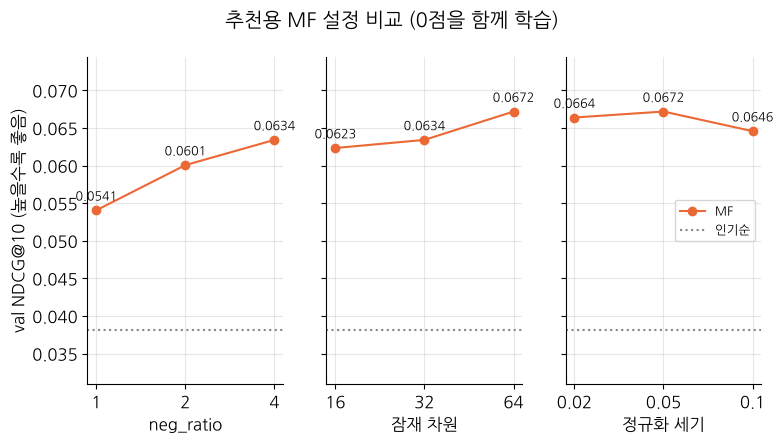

,neg_ratio,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,1,1.7405,0.0541,2,51.3
1,2,1.9427,0.0601,4,97.9
2,4,2.2645,0.0634,2,89.6


,n_factors,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,16,2.2749,0.0623,2,60.3
1,32,2.2645,0.0634,2,89.6
2,64,2.2312,0.0672,4,226.0


,reg,val_rmse,val_ndcg@10,best_epoch,train_seconds
0,0.02,2.2163,0.0664,2,150.2
1,0.05,2.2312,0.0672,4,226.0
2,0.10,2.3060,0.0646,4,226.8


In [6]:
ranking_panels = [
    ("neg_ratio", "neg_ratio", sweep_table("ranking", ranking_start, "neg_ratio", NEG_VALUES)),
    ("n_factors", "잠재 차원", sweep_table("ranking", ranking_after_neg, "n_factors", RANKING_FACTOR_VALUES)),
    ("reg", "정규화 세기", sweep_table("ranking", ranking_after_factors, "reg", RANKING_REG_VALUES)),
]
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, (name, label, table) in zip(axes, ranking_panels):
    ax.plot(table[name].astype(str), table["val_ndcg@10"], color=MODEL_COLORS["mf"], marker="o", label="MF")
    ax.axhline(popularity_ndcg, color=MODEL_COLORS["baseline"], linestyle=":", label="인기순")
    for x, y in zip(table[name].astype(str), table["val_ndcg@10"]):
        ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
    ax.set_xlabel(label)
axes[0].set_ylabel("val NDCG@10 (높을수록 좋음)")
axes[0].margins(y=0.25)
axes[-1].legend(loc="center right", fontsize=9)
fig.suptitle("추천용 MF 설정 비교 (0점을 함께 학습)")
save(fig, "C2_mf_tuning_ranking")
plt.show()
for name, label, table in ranking_panels:
    display(table.round(4))

## 3. neg_ratio에 따른 별점 예측과 추천의 차이

0점을 섞지 않은 모델(별점 예측용 최종 설정)과 섞은 모델(neg_ratio 1·2·4)의 검증 RMSE와 val NDCG@10을 나란히 봅니다.

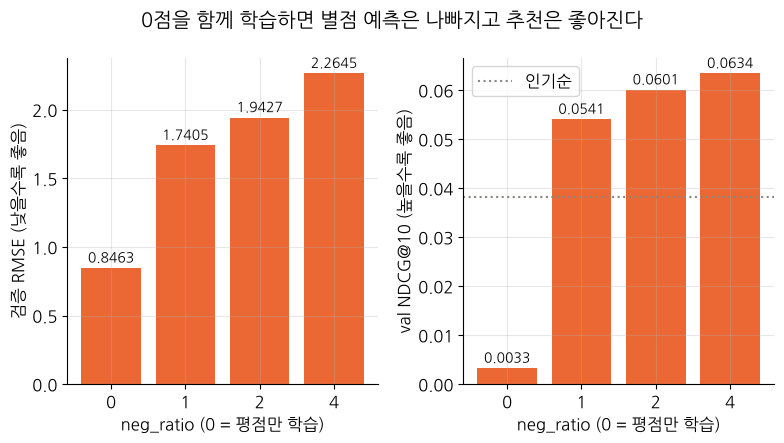

,neg_ratio,val_rmse,val_ndcg@10
0,0,0.8463,0.0033
1,1,1.7405,0.0541
2,2,1.9427,0.0601
3,4,2.2645,0.0634


In [7]:
tradeoff = pd.concat([
    pd.DataFrame([finished[("rating", rating_best)]]),
    pd.DataFrame([finished[("ranking", replace(ranking_start, neg_ratio=value))] for value in NEG_VALUES]),
])[["neg_ratio", "val_rmse", "val_ndcg@10"]].reset_index(drop=True)
tradeoff.to_csv(RESULT_DIR / "C2_neg_ratio_tradeoff.csv", index=False)

fig, (left, right) = plt.subplots(1, 2)
labels = tradeoff["neg_ratio"].astype(str)
left.bar(labels, tradeoff["val_rmse"], color=MODEL_COLORS["mf"])
left.set_xlabel("neg_ratio (0 = 평점만 학습)")
left.set_ylabel("검증 RMSE (낮을수록 좋음)")
right.bar(labels, tradeoff["val_ndcg@10"], color=MODEL_COLORS["mf"])
right.axhline(popularity_ndcg, color=MODEL_COLORS["baseline"], linestyle=":", label="인기순")
right.set_xlabel("neg_ratio (0 = 평점만 학습)")
right.set_ylabel("val NDCG@10 (높을수록 좋음)")
right.legend()
for ax, column in [(left, "val_rmse"), (right, "val_ndcg@10")]:
    for x, y in zip(labels, tradeoff[column]):
        ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=10)
fig.suptitle("0점을 함께 학습하면 별점 예측은 나빠지고 추천은 좋아진다")
save(fig, "C2_mf_rmse_vs_ndcg")
plt.show()
tradeoff.round(4)

## 4. 최종 설정

고른 설정을 `results/collaborative_filtering/C2_selected_config.json`에 저장합니다.
`n_epochs`는 early stopping으로 멈춘 epoch로 바꿔 저장합니다. 그래서 `load_selected_mf(용도).fit(split.train)`만 해도 같은 모델이 나옵니다.

In [8]:
selected = {}
for purpose, config in [("rating", rating_best), ("ranking", ranking_best)]:
    record = finished[(purpose, config)]
    selected[purpose] = {
        "run_id": record["run_id"],
        "config": asdict(replace(config, n_epochs=int(record["best_epoch"]))),
        "criterion": "lowest val RMSE" if purpose == "rating" else f"highest val NDCG@10 on {TUNING_USERS} val users (seed 42)",
        "val_rmse": float(record["val_rmse"]),
        "val_ndcg@10": float(record["val_ndcg@10"]),
        "train_source": "split.train",
        "final_evaluation_performed": False,
    }
save_selected(selected)
pd.DataFrame({purpose: {**item["config"], "val_rmse": item["val_rmse"], "val_ndcg@10": item["val_ndcg@10"]} for purpose, item in selected.items()})

,rating,ranking
n_factors,64.000000,64.00000
lr,0.005000,0.02000
reg,0.050000,0.05000
n_epochs,39.000000,4.00000
batch_size,2048.000000,2048.00000
neg_ratio,0.000000,4.00000
patience,2.000000,2.00000
fold_in_reg,5.000000,5.00000
seed,42.000000,42.00000
val_rmse,0.846315,2.23115


In [9]:
all_runs = pd.DataFrame(runs)
all_runs[["run_id", "purpose", "n_factors", "lr", "reg", "neg_ratio", "best_epoch", "epochs_run", "val_rmse", "val_ndcg@10", "train_seconds"]].round(4)

,run_id,purpose,n_factors,lr,reg,neg_ratio,best_epoch,epochs_run,val_rmse,val_ndcg@10,train_seconds
0,rating-01,rating,32,0.005,0.05,0,39,40,0.8473,0.0029,170.3
1,rating-02,rating,32,0.010,0.05,0,21,23,0.8477,0.0031,99.2
2,rating-03,rating,32,0.020,0.05,0,11,13,0.8489,0.0027,53.1
3,rating-04,rating,8,0.005,0.05,0,40,40,0.8496,0.0033,57.1
4,rating-05,rating,16,0.005,0.05,0,40,40,0.8487,0.0037,93.9
5,rating-06,rating,64,0.005,0.05,0,39,40,0.8463,0.0033,289.5
6,rating-07,rating,64,0.005,0.02,0,17,19,0.8574,0.0064,136.7
7,rating-08,rating,64,0.005,0.10,0,10,12,0.8626,0.0011,89.5
8,ranking-09,ranking,32,0.020,0.05,1,2,4,1.7405,0.0541,51.3
9,ranking-10,ranking,32,0.020,0.05,2,4,6,1.9427,0.0601,97.9
